# Compressed Air Energy Storage (CAES) — Variant 1b
## Single-Stage, No Thermal Storage, Constant-Pressure Reservoir
**Model Overview:**
Variant 1b stores electrical energy during charge by compressing ambient air through a single-stage uncooled compressor and aftercooling train into an isobaric (constant-pressure, variable-volume) reservoir at $P_{\text{max}} = 16\text{ bar}$. In accordance with the project specification (Section 3, "Large-span coolers"), the large-span aftercooler ($410^\circ\text{C} \to 25^\circ\text{C}$) is split into two counter-flow heat exchangers in series of equal air-side surface area ($A_{\text{air},1} = A_{\text{air},2}$). During discharge, the stored air is released at constant pressure, heated in a combustor to the turbine inlet temperature ($\text{TIT} = 550^\circ\text{C}$), and expanded through a single-stage turbine to ambient pressure delivering $1\text{ MW}$ shaft power for $4\text{ h}$ ($4\text{ MWh}$).

**Own Engineering Assumptions (Not in PDF):**
1. Combustor relative pressure drop: $\Delta p / p = 4\%$ (`dp_comb_rel = 0.04`).
2. Methane lower heating value: $\text{LHV} = 50.0\text{ MJ/kg}$.
3. Methane chemical exergy factor: $e_{\text{chem}} = 1.04 \times \text{LHV}$.
4. Cooling water mass flow rate: $\dot{m}_{\text{water}} = 6.0\text{ kg/s}$ (ensures water warms from $15^\circ\text{C}$ to $\approx 57^\circ\text{C}$, remaining liquid with no phase change).
5. Storage reservoir vessel: Cylindrical Stainless Steel 304 shell ($D_{\text{out}} = 8.0\text{ m}$, thickness $t = 0.12\text{ m}$, $\rho = 7955\text{ kg/m³}$, $c_p = 500\text{ J/(kg K)}$, $k = 16\text{ W/(m K)}$, internal natural convection $h = 50\text{ W/(m²K)}$).

## 1. Imports and Thermodynamic Backends

In [70]:
import numpy as np
from IPython.display import Markdown, display
from CoolProp.CoolProp import PropsSI
from caldis.core.system import System
from caldis.components import FluidBoundary, Compressor, SizingHX, CombustionChamber, Turbine
from caldis.components.vessels.tank import TankConstP
from caldis.fluids import CoolPropBackend
from caldis.solvers import simulate

# Fluid property backends (CoolProp)
be_air = CoolPropBackend("Air")
be_fuel = CoolPropBackend("Methane")
be_water = CoolPropBackend("Water")


## 2. Given Parameters from the PDF (Section 3)

In [71]:
# Reference conditions and targets
T0 = 15.0 + 273.15  # [K] Ambient temperature (15 °C)
P0 = 1.013e5  # [Pa] Ambient pressure (1.013 bar)
Pmax = 16.0e5  # [Pa] Nominal storage pressure (16 bar)
Ttit = 550.0 + 273.15  # [K] Turbine inlet temperature (550 °C)
W_target = 1.0e6  # [W] Target net shaft electrical power (1 MW)
t_discharge = 4.0 * 3600.0  # [s] Discharge duration (4 h -> 4 MWh delivered)
t_charge = 4.0 * 3600.0  # [s] Charge duration (4 h)

# Fixed component efficiencies
Eta_ISC = 0.85  # [-] Compressor isentropic efficiency
Eta_IST = 0.88  # [-] Turbine isentropic efficiency
Eta_Mech = 0.98  # [-] Mechanical / generator efficiency
Eta_Fuel = 0.40  # [-] Reference fuel-to-electricity efficiency

# Heat exchanger specifications
delta_T_pinch = 10.0  # [K] Cooler pinch temperature difference (air cooled to T0 + 10 K)
h_film_air = 50.0  # [W/(m²·K)] Air-side convective film coefficient
h_film_water = 1000.0  # [W/(m²·K)] Water-side convective film coefficient
Ratio_Area_cold_to_hot = 1.0 / 15.0  # [-] Water/air area ratio (extended finned air side)


## 3. Engineering Assumptions (Not in PDF)

In [72]:
# System and fuel assumptions
dp_comb_rel = 0.04  # [-] Combustor relative pressure drop # ASSUMPTION (not in PDF)
LHV_fuel = 50.0e6  # [J/kg] Methane lower heating value # ASSUMPTION (not in PDF)
factor_ex_fuel = 1.04  # [-] Methane chemical exergy factor (1.04 * LHV) # ASSUMPTION (not in PDF)
Mdot_water_Charge = 6.0  # [kg/s] Cooling water mass flow rate # ASSUMPTION (not in PDF)
Mdot_fuel_guess = 0.286  # [kg/s] Initial guess for fuel flow rate # ASSUMPTION (not in PDF)

# Cylindrical steel pressure vessel properties (Stainless Steel 304) # ASSUMPTION (not in PDF)
Density_Steel = 7955.0  # [kg/m³] Metal density
Cp_Steel = 500.0  # [J/(kg·K)] Metal specific heat capacity
k_steel = 16.0  # [W/(m·K)] Metal thermal conductivity
Diameter_Tank_out = 8.0  # [m] Outer vessel diameter
Thickness_wall = 0.12  # [m] Shell wall thickness
h_conv_in = 50.0  # [W/(m²·K)] Internal air natural convection coefficient

# Energy conversion constant and ambient reference state
MWh = 3.6e9  # [J/MWh] Conversion factor
h0_air = PropsSI("H", "T", T0, "P", P0, "Air")  # [J/kg] Ambient air reference enthalpy
s0_air = PropsSI("S", "T", T0, "P", P0, "Air")  # [J/(kg·K)] Ambient air reference entropy

# Vessel geometry independent of volume # ASSUMPTION (not in PDF)
r_out = Diameter_Tank_out / 2.0
r_in = r_out - Thickness_wall
r_mid = 0.5 * (r_out + r_in)
Area_Tank_in_cs = np.pi * (r_in**2)
Area_Tank_Shell_cs = np.pi * (r_out**2 - r_in**2)


## 4. Helper Functions

In [73]:
def flow_exergy_rate(mdot, p, h, fluid="Air"):
    """Calculate physical flow exergy rate [W] relative to ambient dead state (T0, P0)."""
    h0 = PropsSI("H", "T", T0, "P", P0, fluid)
    s0 = PropsSI("S", "T", T0, "P", P0, fluid)
    s = PropsSI("S", "P", p, "H", h, fluid)
    return np.abs(mdot) * ((h - h0) - T0 * (s - s0))

def show_table(title, rows):
    """Render result rows as a Markdown table in the notebook."""
    headers = ("Name", "Definition/Equation", "Value", "Unit")
    lines = [f"## {title}", "| " + " | ".join(headers) + " |", "|" + "|".join("---" for _ in headers) + "|"]
    for row in rows:
        cells = [str(value).replace("|", "\\|").replace("\n", " ") for value in row]
        lines.append("| " + " | ".join(cells) + " |")
    display(Markdown("\n".join(lines)))


## 5. Discharge Subsystem: Design Sizing & Dynamic Simulation
The discharge cycle extracts compressed air from the reservoir, adds combustion heat up to $\text{TIT} = 550^\circ\text{C}$, and expands the air through the turbine to ambient pressure. Sizing the required air mass is done first to determine the exact mass that the charge subsystem must replenish.

In [74]:
# 1. Design point thermodynamic estimate
P_turb_in = Pmax * (1.0 - dp_comb_rel)
h_turb_in = PropsSI("H", "T", Ttit, "P", P_turb_in, "Air")
s_turb_in = PropsSI("S", "T", Ttit, "P", P_turb_in, "Air")
h_turb_out_s = PropsSI("H", "P", P0, "S", s_turb_in, "Air")
w_sp = Eta_Mech * Eta_IST * (h_turb_in - h_turb_out_s)
Mdot_dis_design = W_target / w_sp
Mass_dis_total = Mdot_dis_design * t_discharge
h_tank_dis = PropsSI("H", "T", T0, "P", Pmax, "Air")
rho_tank_dis = PropsSI("D", "T", T0, "P", Pmax, "Air")
V_initial_estimate = Mass_dis_total / rho_tank_dis

# Volume-dependent vessel thermal properties for nominal Pmax
Length_Tank = V_initial_estimate / Area_Tank_in_cs
area_surf_in = 2.0 * np.pi * r_in * Length_Tank
vol_shell = Area_Tank_Shell_cs * Length_Tank
Cwall = Density_Steel * vol_shell * Cp_Steel
r_conv = 1.0 / (h_conv_in * area_surf_in)
r_cond = np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank)
UA_wall = 1.0 / (r_conv + r_cond)

# 2. Volume sizing iteration loop (target V_end = 0 within 0.1 m³)
V_guess = V_initial_estimate
err = float("inf")
iter_count = 0
print(f"Starting discharge simulation...")
while abs(err) >= 0.1:
    Source_Discharge = FluidBoundary(name="Source_Discharge", T=T0, mdot=0, backend=be_air)
    Comb_Discharge = CombustionChamber(name="Comb_Discharge", backend_air=be_air, backend_fuel=be_fuel, LHV=LHV_fuel, eta_comb=1.0, dp_rel=dp_comb_rel)
    FuelIn_Discharge = FluidBoundary(name="FuelIn_Discharge", p=P0, T=T0, backend=be_fuel)
    Turb_Discharge = Turbine(name="Turb_Discharge", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
    Tank_Discharge = TankConstP(name="Tank_Discharge", backend=be_air, p=Pmax, h_init=h_tank_dis, V_init=V_guess, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0.0)
    Exhaust_Discharge = FluidBoundary(name="Exhaust_Discharge", p=P0, backend=be_air)

    Sys_Discharge = System("Sys_Discharge")
    Sys_Discharge.add(Source_Discharge, Tank_Discharge, Turb_Discharge, Comb_Discharge, FuelIn_Discharge, Exhaust_Discharge)
    Sys_Discharge.connect(Source_Discharge.port, Tank_Discharge.inl)
    Sys_Discharge.connect(Tank_Discharge.out, Comb_Discharge.air_in)
    Sys_Discharge.connect(FuelIn_Discharge.port, Comb_Discharge.fuel_in)
    Sys_Discharge.connect(Comb_Discharge.gas_out, Turb_Discharge.inl)
    Sys_Discharge.connect(Turb_Discharge.out, Exhaust_Discharge.port)

    Sys_Discharge.add_constraint(lambda: be_air.T(Comb_Discharge.gas_out.p, Comb_Discharge.gas_out.h) - Ttit, "TIT_550C")
    Sys_Discharge.add_constraint(lambda: Eta_Mech * Turb_Discharge.inl.mdot * (Turb_Discharge.inl.h - Turb_Discharge.out.h) - W_target, "Wdot_1MW")

    Sys_Discharge.set_start_port(Tank_Discharge.out, p=Pmax, T=Tank_Discharge.out.T, mdot=-Mdot_dis_design)
    Sys_Discharge.set_start_port(FuelIn_Discharge.port, p=P0, T=T0, mdot=-Mdot_fuel_guess)
    Sys_Discharge.set_start_port(Comb_Discharge.air_in, p=Tank_Discharge.out.p, T=Tank_Discharge.out.T, mdot=Mdot_dis_design)
    Sys_Discharge.set_start_port(Comb_Discharge.gas_out, p=Comb_Discharge.gas_out.p, T=Ttit, mdot=-Mdot_dis_design)
    Sys_Discharge.set_start_port(Turb_Discharge.inl, p=Comb_Discharge.gas_out.p, T=Ttit, mdot=Mdot_dis_design)
    Sys_Discharge.set_start_port(Turb_Discharge.out, p=P0, T=Turb_Discharge.out.T, mdot=-Mdot_dis_design)
    Sys_Discharge.set_start_port(Exhaust_Discharge.port, p=P0, T=Turb_Discharge.out.T, mdot=Mdot_dis_design)
    Sys_Discharge.init_starts()

    Res_Discharge = simulate(Sys_Discharge, t_end=t_discharge, dt=240, init="consistent", progress=False)
    err = Res_Discharge.Tank_Discharge.V[-1]
    iter_count += 1
    print(f"  Iteration {iter_count}: V_init = {V_guess:.3f} m³, V_end = {Res_Discharge.Tank_Discharge.V[-1]:.3f} m³, Error = {err:+.3f} m³")
    V_guess -= err

# Mass of air needed to replenish the reservoir
V_start_dis = Res_Discharge.Tank_Discharge.V[0]
Density_dis_air = PropsSI("D", "T", Tank_Discharge.out.T, "P", Tank_Discharge.out.p, "Air")
Mass_air_dis = V_start_dis * Density_dis_air
Mdot_Charge = Mass_air_dis / t_charge


Starting discharge simulation...
  Iteration 1: V_init = 1879.688 m³, V_end = 20.650 m³, Error = +20.650 m³
  Iteration 2: V_init = 1859.038 m³, V_end = 0.796 m³, Error = +0.796 m³
  Iteration 3: V_init = 1858.242 m³, V_end = 0.031 m³, Error = +0.031 m³


## 6. Charge Subsystem: Two Coolers in Series & Simulation
The charge subsystem draws ambient air at $(T_0, P_0)$, compresses it through a single-stage uncooled compressor, and cools it through two equal-area counter-flow heat exchangers in series down to $T_0 + 10\text{ K} = 25^\circ\text{C}$ before injection into the constant-pressure storage reservoir.

In [75]:
T_cooler_out = T0 + delta_T_pinch
h_tank_charge = PropsSI("H", "T", T_cooler_out, "P", Pmax, "Air")
print(f"Starting discharge simulation...")

Source_Charge = FluidBoundary(name="Source_Charge", p=P0, T=T0, mdot=-Mdot_Charge, backend=be_air)
Comp_Charge = Compressor(name="Comp_Charge", backend=be_air, eta_is=Eta_ISC)
Hex1_Charge = SizingHX(name="Hex1_Charge", backend_hot=be_air, backend_cold=be_water, h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)
Hex2_Charge = SizingHX(name="Hex2_Charge", backend_hot=be_air, backend_cold=be_water, h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)
WaterIn_Charge = FluidBoundary(name="WaterIn_Charge", p=P0, T=T0, mdot=-Mdot_water_Charge, backend=be_water)
WaterOut_Charge = FluidBoundary(name="WaterOut_Charge", backend=be_water)
Tank_Charge = TankConstP(name="Tank_Charge", backend=be_air, p=Pmax, h_init=h_tank_charge, V_init=0.0, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0.0)
Closed_Charge = FluidBoundary(name="Closed_Charge", p=None, T=None, h=None, mdot=0.0, backend=be_air)

Sys_Charge = System("Sys_Charge")
Sys_Charge.add(Source_Charge, Comp_Charge, Hex1_Charge, Hex2_Charge, WaterIn_Charge, WaterOut_Charge, Tank_Charge, Closed_Charge)

# Air side series: Source -> Comp -> Hex1 (hot) -> Hex2 (hot) -> Tank -> Closed
Sys_Charge.connect(Source_Charge.port, Comp_Charge.inl)
Sys_Charge.connect(Comp_Charge.out, Hex1_Charge.hot_in)
Sys_Charge.connect(Hex1_Charge.hot_out, Hex2_Charge.hot_in)
Sys_Charge.connect(Hex2_Charge.hot_out, Tank_Charge.inl)
Sys_Charge.connect(Tank_Charge.out, Closed_Charge.port)

# Water side series counter-current: WaterIn -> Hex2 (cold) -> Hex1 (cold) -> WaterOut
Sys_Charge.connect(WaterIn_Charge.port, Hex2_Charge.cold_in)
Sys_Charge.connect(Hex2_Charge.cold_out, Hex1_Charge.cold_in)
Sys_Charge.connect(Hex1_Charge.cold_out, WaterOut_Charge.port)

# Constraints: Air outlet at 25 °C and equal exchanger conductance
Sys_Charge.add_constraint(lambda: be_air.T(Hex2_Charge.hot_out.p, Hex2_Charge.hot_out.h) - T_cooler_out, name="cooler_outlet_temperature")
Sys_Charge.add_constraint(lambda: Hex1_Charge.UA - Hex2_Charge.UA, name="equal_hex_areas")

T_air_mid_guess = 150.0 + 273.15
T_water_mid_guess = 30.0 + 273.15
T_water_out_guess = 55.0 + 273.15

Sys_Charge.set_start_port(Comp_Charge.inl, p=P0, T=T0, mdot=Mdot_Charge)
Sys_Charge.set_start_port(Comp_Charge.out, p=Pmax, T=410.0 + 273.15, mdot=-Mdot_Charge)
Sys_Charge.set_start_port(Hex1_Charge.hot_in, p=Pmax, T=410.0 + 273.15, mdot=Mdot_Charge)
Sys_Charge.set_start_port(Hex1_Charge.hot_out, p=Pmax, T=T_air_mid_guess, mdot=-Mdot_Charge)
Sys_Charge.set_start_port(Hex1_Charge.cold_in, p=P0, T=T_water_mid_guess, mdot=Mdot_water_Charge)
Sys_Charge.set_start_port(Hex1_Charge.cold_out, p=P0, T=T_water_out_guess, mdot=-Mdot_water_Charge)

Sys_Charge.set_start_port(Hex2_Charge.hot_in, p=Pmax, T=T_air_mid_guess, mdot=Mdot_Charge)
Sys_Charge.set_start_port(Hex2_Charge.hot_out, p=Pmax, T=T_cooler_out, mdot=-Mdot_Charge)
Sys_Charge.set_start_port(Hex2_Charge.cold_in, p=P0, T=T0, mdot=Mdot_water_Charge)
Sys_Charge.set_start_port(Hex2_Charge.cold_out, p=P0, T=T_water_mid_guess, mdot=-Mdot_water_Charge)

Sys_Charge.set_start_port(Tank_Charge.inl, p=Pmax, T=T_cooler_out, mdot=Mdot_Charge)
Sys_Charge.set_start_port(Tank_Charge.out, p=Pmax, T=T_cooler_out, mdot=0.0)
Sys_Charge.init_starts()

Res_Charge = simulate(Sys_Charge, t_end=t_charge, dt=240, init="consistent", progress=False)

UA1_Charge = Hex1_Charge.UA
UA2_Charge = Hex2_Charge.UA
A_air1_Charge = Hex1_Charge.A_hot
A_air2_Charge = Hex2_Charge.A_hot
A_air_total_Charge = A_air1_Charge + A_air2_Charge


Starting discharge simulation...


## 7. Energy and Exergy Balances
Evaluates first-law and second-law energy/exergy flows and component destructions. Prints balance closure residuals.

In [76]:
# --- Charge Energy Balance ---
t_ch = Res_Charge.time
W_comp_fluid_Charge = np.trapezoid(np.abs(Res_Charge.Comp_Charge.Wdot), x=t_ch) / MWh
W_comp_Charge = W_comp_fluid_Charge / Eta_Mech
Loss_mech_comp_Charge = W_comp_Charge - W_comp_fluid_Charge

Q_cooler1_Charge = np.trapezoid(Res_Charge.Hex1_Charge.Qdot, x=t_ch) / MWh
Q_cooler2_Charge = np.trapezoid(Res_Charge.Hex2_Charge.Qdot, x=t_ch) / MWh
Q_cooler_Charge = Q_cooler1_Charge + Q_cooler2_Charge

H_source_Charge = np.trapezoid(Res_Charge.Source_Charge.port.mdot * (Res_Charge.Source_Charge.port.h - h0_air), x=t_ch) / MWh
H_tank_in_Charge = np.trapezoid(Res_Charge.Tank_Charge.fluid.inl.mdot * (Res_Charge.Tank_Charge.fluid.inl.h - h0_air), x=t_ch) / MWh
Energy_residual_Charge = H_source_Charge + W_comp_Charge - Loss_mech_comp_Charge - Q_cooler_Charge - H_tank_in_Charge

# --- Charge Exergy Balance ---
X_source_Charge = np.trapezoid(flow_exergy_rate(Res_Charge.Source_Charge.port.mdot, Res_Charge.Source_Charge.port.p, Res_Charge.Source_Charge.port.h), x=t_ch) / MWh
X_comp_work_Charge = np.trapezoid(np.abs(Res_Charge.Comp_Charge.Wdot), x=t_ch) / MWh
X_comp_in_Charge = flow_exergy_rate(Res_Charge.Comp_Charge.inl.mdot, Res_Charge.Comp_Charge.inl.p, Res_Charge.Comp_Charge.inl.h)
X_comp_out_Charge = flow_exergy_rate(Res_Charge.Comp_Charge.out.mdot, Res_Charge.Comp_Charge.out.p, Res_Charge.Comp_Charge.out.h)

X_tank_in_Charge = np.trapezoid(flow_exergy_rate(Res_Charge.Tank_Charge.fluid.inl.mdot, Res_Charge.Tank_Charge.fluid.inl.p, Res_Charge.Tank_Charge.fluid.inl.h), x=t_ch) / MWh
X_coolant_gain_Charge = np.trapezoid(flow_exergy_rate(Res_Charge.Hex1_Charge.cold_out.mdot, Res_Charge.Hex1_Charge.cold_out.p, Res_Charge.Hex1_Charge.cold_out.h, "Water") - flow_exergy_rate(Res_Charge.Hex2_Charge.cold_in.mdot, Res_Charge.Hex2_Charge.cold_in.p, Res_Charge.Hex2_Charge.cold_in.h, "Water"), x=t_ch) / MWh

X_dest_comp_Charge = np.trapezoid(np.abs(Res_Charge.Comp_Charge.Wdot) + X_comp_in_Charge - X_comp_out_Charge, x=t_ch) / MWh

X_dest_hex1_Charge = np.trapezoid((flow_exergy_rate(Res_Charge.Hex1_Charge.hot_in.mdot, Res_Charge.Hex1_Charge.hot_in.p, Res_Charge.Hex1_Charge.hot_in.h) - flow_exergy_rate(Res_Charge.Hex1_Charge.hot_out.mdot, Res_Charge.Hex1_Charge.hot_out.p, Res_Charge.Hex1_Charge.hot_out.h)) - (flow_exergy_rate(Res_Charge.Hex1_Charge.cold_out.mdot, Res_Charge.Hex1_Charge.cold_out.p, Res_Charge.Hex1_Charge.cold_out.h, "Water") - flow_exergy_rate(Res_Charge.Hex1_Charge.cold_in.mdot, Res_Charge.Hex1_Charge.cold_in.p, Res_Charge.Hex1_Charge.cold_in.h, "Water")), x=t_ch) / MWh

X_dest_hex2_Charge = np.trapezoid((flow_exergy_rate(Res_Charge.Hex2_Charge.hot_in.mdot, Res_Charge.Hex2_Charge.hot_in.p, Res_Charge.Hex2_Charge.hot_in.h) - flow_exergy_rate(Res_Charge.Hex2_Charge.hot_out.mdot, Res_Charge.Hex2_Charge.hot_out.p, Res_Charge.Hex2_Charge.hot_out.h)) - (flow_exergy_rate(Res_Charge.Hex2_Charge.cold_out.mdot, Res_Charge.Hex2_Charge.cold_out.p, Res_Charge.Hex2_Charge.cold_out.h, "Water") - flow_exergy_rate(Res_Charge.Hex2_Charge.cold_in.mdot, Res_Charge.Hex2_Charge.cold_in.p, Res_Charge.Hex2_Charge.cold_in.h, "Water")), x=t_ch) / MWh

X_dest_cooler_Charge = X_dest_hex1_Charge + X_dest_hex2_Charge
Exergy_residual_Charge = X_comp_work_Charge + X_source_Charge - (X_tank_in_Charge + X_coolant_gain_Charge + X_dest_comp_Charge + X_dest_cooler_Charge)

# --- Discharge Energy & Exergy Balances ---
t_dis = Res_Discharge.time
W_turb_Discharge = np.trapezoid(Res_Discharge.Turb_Discharge.Wdot, x=t_dis) / MWh
Loss_mech_turb_Discharge = np.trapezoid(Res_Discharge.Turb_Discharge.Wdot * ((1.0 - Eta_Mech) / Eta_Mech), x=t_dis) / MWh
Q_fuel_Discharge = np.trapezoid(Res_Discharge.Comb_Discharge.Qdot_fuel, x=t_dis) / MWh
Loss_exhaust_Discharge = np.trapezoid(np.abs(Res_Discharge.Turb_Discharge.out.mdot) * (Res_Discharge.Turb_Discharge.out.h - h0_air), x=t_dis) / MWh

X_air_in_Discharge = np.trapezoid(flow_exergy_rate(Res_Discharge.Comb_Discharge.air_in.mdot, Res_Discharge.Comb_Discharge.air_in.p, Res_Discharge.Comb_Discharge.air_in.h), x=t_dis) / MWh
X_fuel_in_Discharge = np.trapezoid(factor_ex_fuel * Res_Discharge.Comb_Discharge.Qdot_fuel, x=t_dis) / MWh
X_input_Discharge = X_air_in_Discharge + X_fuel_in_Discharge

X_loss_exhaust_Discharge = np.trapezoid(flow_exergy_rate(Res_Discharge.Turb_Discharge.out.mdot, Res_Discharge.Turb_Discharge.out.p, Res_Discharge.Turb_Discharge.out.h), x=t_dis) / MWh

X_dest_comb_Discharge = np.trapezoid(flow_exergy_rate(Res_Discharge.Comb_Discharge.air_in.mdot, Res_Discharge.Comb_Discharge.air_in.p, Res_Discharge.Comb_Discharge.air_in.h) + factor_ex_fuel * Res_Discharge.Comb_Discharge.Qdot_fuel - flow_exergy_rate(Res_Discharge.Turb_Discharge.inl.mdot, Res_Discharge.Turb_Discharge.inl.p, Res_Discharge.Turb_Discharge.inl.h), x=t_dis) / MWh

X_dest_turb_Discharge = np.trapezoid(flow_exergy_rate(Res_Discharge.Turb_Discharge.inl.mdot, Res_Discharge.Turb_Discharge.inl.p, Res_Discharge.Turb_Discharge.inl.h) - flow_exergy_rate(Res_Discharge.Turb_Discharge.out.mdot, Res_Discharge.Turb_Discharge.out.p, Res_Discharge.Turb_Discharge.out.h) - Res_Discharge.Turb_Discharge.Wdot, x=t_dis) / MWh

Exergy_residual_Discharge = X_input_Discharge - (W_turb_Discharge + X_loss_exhaust_Discharge + X_dest_comb_Discharge + X_dest_turb_Discharge)

print(f"Charge energy residual:    {Energy_residual_Charge:.6f} MWh")
print(f"Charge exergy residual:    {Exergy_residual_Charge:.6f} MWh")
print(f"Discharge exergy residual: {Exergy_residual_Discharge:.6f} MWh")


Charge energy residual:    0.000438 MWh
Charge exergy residual:    -0.000089 MWh
Discharge exergy residual: 0.000000 MWh


## 8. Summary Deliverable Tables (Tables 1, 2, and 3)

In [77]:
# Metrics calculation
W_fuel_eq_Discharge = Eta_Fuel * Q_fuel_Discharge
W_in_weighted = W_comp_Charge + W_fuel_eq_Discharge
eta_RT = (W_turb_Discharge / W_in_weighted) * 100.0
elec_share = (W_comp_Charge / W_in_weighted) * 100.0
fuel_share = (W_fuel_eq_Discharge / W_in_weighted) * 100.0

V_end_charge = Res_Charge.Tank_Charge.fluid.V[-1]
T_comp_out_C = be_air.T(Res_Charge.Comp_Charge.out.p[-1], Res_Charge.Comp_Charge.out.h[-1]) - 273.15
T_air_mid_C = be_air.T(Res_Charge.Hex1_Charge.hot_out.p[-1], Res_Charge.Hex1_Charge.hot_out.h[-1]) - 273.15
T_air_out_C = be_air.T(Res_Charge.Hex2_Charge.hot_out.p[-1], Res_Charge.Hex2_Charge.hot_out.h[-1]) - 273.15
T_water_mid_C = be_water.T(Res_Charge.Hex2_Charge.cold_out.p[-1], Res_Charge.Hex2_Charge.cold_out.h[-1]) - 273.15
T_water_out_C = be_water.T(Res_Charge.Hex1_Charge.cold_out.p[-1], Res_Charge.Hex1_Charge.cold_out.h[-1]) - 273.15

Mass_fuel_dis = np.trapezoid(np.abs(Res_Discharge.FuelIn_Discharge.port.mdot), x=t_dis)
Mass_air_dis_integral = np.trapezoid(np.abs(Res_Discharge.Comb_Discharge.air_in.mdot), x=t_dis)
Mass_air_stored = Res_Charge.Tank_Charge.fluid.M[-1] - Res_Charge.Tank_Charge.fluid.M[0]

In [78]:
# --- Table 1: Comparison Criteria Asked by the PDF ---
t1_rows = [
    ("Round-trip efficiency", "W_turb / (W_comp + eta_f * Q_fuel)", f"{eta_RT:.2f}", "%"),
    ("Total cooler air-side area", "Hex1.A_hot + Hex2.A_hot", f"{A_air_total_Charge:.1f}", "m²"),
    ("Required volume at end of charge", "V_end,charge (warmest state)", f"{V_end_charge:.1f}", "m³"),
    ("Volume at start of discharge", "V_start,discharge (reference state)", f"{V_start_dis:.1f}", "m³"),
    ("Electrical input share", "W_comp / (W_comp + eta_f * Q_fuel)", f"{elec_share:.1f}", "%"),
    ("Fuel input share", "(eta_f * Q_fuel) / (W_comp + eta_f * Q_fuel)", f"{fuel_share:.1f}", "%"),
    ("Maximum temperatures reached", "T_comp,out / TIT", f"{T_comp_out_C:.1f} / {Ttit - 273.15:.1f}", "°C"),
]
show_table("Table 1 - Comparison criteria asked by the PDF (Variant 1b)", t1_rows)

# --- Table 2: Charge Cycle Results ---
t2_rows = [
    ("Charge air mass flow rate", "M_air / t_charge", f"{Mdot_Charge:.4f}", "kg/s"),
    ("Compressor outlet air temperature", "T(Comp.out)", f"{T_comp_out_C:.1f}", "°C"),
    ("Intermediate air temperature", "T(Hex1.hot_out -> Hex2.hot_in)", f"{T_air_mid_C:.1f}", "°C"),
    ("Final cooler outlet air temp", "T(Hex2.hot_out)", f"{T_air_out_C:.1f}", "°C"),
    ("Cooling water inlet temp", "T(WaterIn)", f"{T0 - 273.15:.1f}", "°C"),
    ("Intermediate cooling water temp", "T(Hex2.cold_out -> Hex1.cold_in)", f"{T_water_mid_C:.1f}", "°C"),
    ("Final cooling water outlet temp", "T(Hex1.cold_out)", f"{T_water_out_C:.1f}", "°C"),
    ("Mean compressor electrical power", "mean(|Wdot_comp|) / eta_mech", f"{np.mean(np.abs(Res_Charge.Comp_Charge.Wdot)) / (1e6 * Eta_Mech):.3f}", "MW"),
    ("Compressor electricity drawn", "int(|Wdot_comp|) / (MWh * eta_mech)", f"{W_comp_Charge:.3f}", "MWh"),
    ("Compressor mechanical loss", "W_comp - W_comp,fluid", f"{Loss_mech_comp_Charge:.3f}", "MWh"),
    ("Cooler 1 conductance", "Hex1.UA", f"{UA1_Charge:.1f}", "W/K"),
    ("Cooler 2 conductance", "Hex2.UA", f"{UA2_Charge:.1f}", "W/K"),
    ("Cooler 1 air-side area", "Hex1.A_hot", f"{A_air1_Charge:.1f}", "m²"),
    ("Cooler 2 air-side area", "Hex2.A_hot", f"{A_air2_Charge:.1f}", "m²"),
    ("Cooler 1 heat rejected", "int(Hex1.Qdot) / MWh", f"{Q_cooler1_Charge:.3f}", "MWh"),
    ("Cooler 2 heat rejected", "int(Hex2.Qdot) / MWh", f"{Q_cooler2_Charge:.3f}", "MWh"),
    ("Total cooler heat rejected", "Q_cooler1 + Q_cooler2", f"{Q_cooler_Charge:.3f}", "MWh"),
    ("Air mass stored", "M_tank,end - M_tank,start", f"{Mass_air_stored:.1f}", "kg"),
    ("Tank volume start / end", "V_tank,start / V_tank,end", f"{Res_Charge.Tank_Charge.fluid.V[0]:.1f} / {V_end_charge:.1f}", "m³"),
    ("Final tank air temperature", "T_fluid,end", f"{Res_Charge.Tank_Charge.T_fluid[-1] - 273.15:.2f}", "°C"),
    ("Exergy stored in tank air", "int(exergy_rate(Tank.inl)) / MWh", f"{X_tank_in_Charge:.3f}", "MWh"),
    ("Compressor exergy destroyed", "int(W_comp + X_in - X_out) / MWh", f"{X_dest_comp_Charge:.3f}", "MWh"),
    ("Cooler 1 exergy destroyed", "int(delta_X_hot - delta_X_cold) / MWh", f"{X_dest_hex1_Charge:.3f}", "MWh"),
    ("Cooler 2 exergy destroyed", "int(delta_X_hot - delta_X_cold) / MWh", f"{X_dest_hex2_Charge:.3f}", "MWh"),
    ("Total cooler exergy destroyed", "X_dest,hex1 + X_dest,hex2", f"{X_dest_cooler_Charge:.3f}", "MWh"),
    ("Charge exergy balance residual", "X_in - sum(X_stored + X_loss + X_dest)", f"{Exergy_residual_Charge:.6f}", "MWh"),
]
show_table("Table 2 - Charge cycle results", t2_rows)

# --- Table 3: Discharge Cycle Results ---
t3_rows = [
    ("Design air mass flow rate", "W_target / (eta_mech * eta_is,t * delta_h_is)", f"{Mdot_dis_design:.4f}", "kg/s"),
    ("Simulated air mass flow rate", "mean(|mdot_air|)", f"{np.mean(np.abs(Res_Discharge.Comb_Discharge.air_in.mdot)):.4f}", "kg/s"),
    ("Simulated fuel mass flow rate", "mean(|mdot_fuel|)", f"{np.mean(np.abs(Res_Discharge.FuelIn_Discharge.port.mdot)):.5f}", "kg/s"),
    ("Total fuel mass consumed", "int(|mdot_fuel|)", f"{Mass_fuel_dis:.1f}", "kg"),
    ("Total air mass discharged", "int(|mdot_air|)", f"{Mass_air_dis_integral:.1f}", "kg"),
    ("Combustion heat supplied", "int(Qdot_fuel) / MWh", f"{Q_fuel_Discharge:.3f}", "MWh"),
    ("Turbine electrical energy delivered", "int(Wdot_turb) / MWh", f"{W_turb_Discharge:.3f}", "MWh"),
    ("Turbine exhaust thermal loss", "int(mdot * (h_out - h0)) / MWh", f"{Loss_exhaust_Discharge:.3f}", "MWh"),
    ("Turbine mechanical loss", "int(Wdot * (1 - eta_m)/eta_m) / MWh", f"{Loss_mech_turb_Discharge:.3f}", "MWh"),
    ("Tank volume start / end", "V_start / V_end", f"{V_start_dis:.1f} / {Res_Discharge.Tank_Discharge.V[-1]:.3f}", "m³"),
    ("Total discharge exergy input", "X_air_in + X_fuel_in", f"{X_input_Discharge:.3f}", "MWh"),
    ("Combustor exergy destroyed", "int(X_air + X_fuel - X_gas_out) / MWh", f"{X_dest_comb_Discharge:.3f}", "MWh"),
    ("Turbine exergy destroyed", "int(X_gas_in - X_exhaust - W_turb) / MWh", f"{X_dest_turb_Discharge:.3f}", "MWh"),
    ("Turbine exhaust exergy loss", "int(flow_exergy(out)) / MWh", f"{X_loss_exhaust_Discharge:.3f}", "MWh"),
    ("Discharge exergy residual", "X_in - (W_turb + X_exhaust + X_dest)", f"{Exergy_residual_Discharge:.6f}", "MWh"),
]
show_table("Table 3 - Discharge cycle results", t3_rows)


## Table 1 - Comparison criteria asked by the PDF (Variant 1b)
| Name | Definition/Equation | Value | Unit |
|---|---|---|---|
| Round-trip efficiency | W_turb / (W_comp + eta_f * Q_fuel) | 59.95 | % |
| Total cooler air-side area | Hex1.A_hot + Hex2.A_hot | 378.3 | m² |
| Required volume at end of charge | V_end,charge (warmest state) | 2015.5 | m³ |
| Volume at start of discharge | V_start,discharge (reference state) | 1858.2 | m³ |
| Electrical input share | W_comp / (W_comp + eta_f * Q_fuel) | 65.2 | % |
| Fuel input share | (eta_f * Q_fuel) / (W_comp + eta_f * Q_fuel) | 34.8 | % |
| Maximum temperatures reached | T_comp,out / TIT | 410.6 / 550.0 | °C |

## Table 2 - Charge cycle results
| Name | Definition/Equation | Value | Unit |
|---|---|---|---|
| Charge air mass flow rate | M_air / t_charge | 2.6122 | kg/s |
| Compressor outlet air temperature | T(Comp.out) | 410.6 | °C |
| Intermediate air temperature | T(Hex1.hot_out -> Hex2.hot_in) | 81.4 | °C |
| Final cooler outlet air temp | T(Hex2.hot_out) | 25.0 | °C |
| Cooling water inlet temp | T(WaterIn) | 15.0 | °C |
| Intermediate cooling water temp | T(Hex2.cold_out -> Hex1.cold_in) | 21.0 | °C |
| Final cooling water outlet temp | T(Hex1.cold_out) | 56.8 | °C |
| Mean compressor electrical power | mean(\|Wdot_comp\|) / eta_mech | 1.088 | MW |
| Compressor electricity drawn | int(\|Wdot_comp\|) / (MWh * eta_mech) | 4.351 | MWh |
| Compressor mechanical loss | W_comp - W_comp,fluid | 0.087 | MWh |
| Cooler 1 conductance | Hex1.UA | 5404.0 | W/K |
| Cooler 2 conductance | Hex2.UA | 5404.0 | W/K |
| Cooler 1 air-side area | Hex1.A_hot | 189.1 | m² |
| Cooler 2 air-side area | Hex2.A_hot | 189.1 | m² |
| Cooler 1 heat rejected | int(Hex1.Qdot) / MWh | 3.582 | MWh |
| Cooler 2 heat rejected | int(Hex2.Qdot) / MWh | 0.612 | MWh |
| Total cooler heat rejected | Q_cooler1 + Q_cooler2 | 4.194 | MWh |
| Air mass stored | M_tank,end - M_tank,start | 37615.0 | kg |
| Tank volume start / end | V_tank,start / V_tank,end | 0.0 / 2015.5 | m³ |
| Final tank air temperature | T_fluid,end | 26.81 | °C |
| Exergy stored in tank air | int(exergy_rate(Tank.inl)) / MWh | 2.382 | MWh |
| Compressor exergy destroyed | int(W_comp + X_in - X_out) / MWh | 0.281 | MWh |
| Cooler 1 exergy destroyed | int(delta_X_hot - delta_X_cold) / MWh | 1.259 | MWh |
| Cooler 2 exergy destroyed | int(delta_X_hot - delta_X_cold) / MWh | 0.065 | MWh |
| Total cooler exergy destroyed | X_dest,hex1 + X_dest,hex2 | 1.323 | MWh |
| Charge exergy balance residual | X_in - sum(X_stored + X_loss + X_dest) | -0.000089 | MWh |

## Table 3 - Discharge cycle results
| Name | Definition/Equation | Value | Unit |
|---|---|---|---|
| Design air mass flow rate | W_target / (eta_mech * eta_is,t * delta_h_is) | 2.5404 | kg/s |
| Simulated air mass flow rate | mean(\|mdot_air\|) | 2.5114 | kg/s |
| Simulated fuel mass flow rate | mean(\|mdot_fuel\|) | 0.02902 | kg/s |
| Total fuel mass consumed | int(\|mdot_fuel\|) | 417.9 | kg |
| Total air mass discharged | int(\|mdot_air\|) | 36163.7 | kg |
| Combustion heat supplied | int(Qdot_fuel) / MWh | 5.805 | MWh |
| Turbine electrical energy delivered | int(Wdot_turb) / MWh | 4.000 | MWh |
| Turbine exhaust thermal loss | int(mdot * (h_out - h0)) / MWh | 1.609 | MWh |
| Turbine mechanical loss | int(Wdot * (1 - eta_m)/eta_m) / MWh | 0.082 | MWh |
| Tank volume start / end | V_start / V_end | 1858.2 / 0.031 | m³ |
| Total discharge exergy input | X_air_in + X_fuel_in | 8.326 | MWh |
| Combustor exergy destroyed | int(X_air + X_fuel - X_gas_out) / MWh | 3.535 | MWh |
| Turbine exergy destroyed | int(X_gas_in - X_exhaust - W_turb) / MWh | 0.466 | MWh |
| Turbine exhaust exergy loss | int(flow_exergy(out)) / MWh | 0.325 | MWh |
| Discharge exergy residual | X_in - (W_turb + X_exhaust + X_dest) | 0.000000 | MWh |

## 9. Parametric Study: Storage Pressure Sweep (10 to 25 bar)


In [87]:
# ==============================================================================
# Parametric Study: Storage Pressure Sweep (10 to 25 bar, Two-Stage Coolers)
# Simulation Loop and Data Aggregation
# ==============================================================================
RUN_SWEEP = True
Pmax_sweep_bar = [10, 12, 14, 16, 18, 20, 22, 24]

if RUN_SWEEP:
    Sweep_Results = []
    print(f"Beginning dynamic simulation across storage pressures: {Pmax_sweep_bar} bar...\n")

    for Pmax_bar_i in Pmax_sweep_bar:
        Pmax_i = Pmax_bar_i * 1e5
        print(f"--- Simulating Pmax = {Pmax_bar_i:.1f} bar ---")

        # Pressure-dependent discharge design conditions
        P_turb_in_Discharge = Pmax_i * (1.0 - dp_comb_rel)
        h_turb_in_Discharge = PropsSI("H", "T", Ttit, "P", P_turb_in_Discharge, "Air")
        s_turb_in_Discharge = PropsSI("S", "T", Ttit, "P", P_turb_in_Discharge, "Air")
        h_turb_out_s_Discharge = PropsSI("H", "P", P0, "S", s_turb_in_Discharge, "Air")
        w_sp_Discharge = Eta_Mech * Eta_IST * (h_turb_in_Discharge - h_turb_out_s_Discharge)
        Mdot_dis_design_Discharge = W_target / w_sp_Discharge
        Mass_dis_total_Discharge = Mdot_dis_design_Discharge * t_discharge
        h_tank_Discharge = PropsSI("H", "T", T0, "P", Pmax_i, "Air")
        rho_tank_Discharge = PropsSI("D", "T", T0, "P", Pmax_i, "Air")

        # Tank wall properties for this pressure's initial volume estimate
        V_initial_Discharge = Mass_dis_total_Discharge / rho_tank_Discharge
        Length_Tank_i = V_initial_Discharge / Area_Tank_in_cs
        Area_Tank_in_surface_i = 2.0 * np.pi * r_in * Length_Tank_i
        Volume_Tank_Shell_i = Area_Tank_Shell_cs * Length_Tank_i
        Cwall_i = Density_Steel * Volume_Tank_Shell_i * Cp_Steel
        R_conv_in_i = 1.0 / (h_conv_in * Area_Tank_in_surface_i)
        R_wall_inner_i = np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank_i)
        UA_wall_i = 1.0 / (R_conv_in_i + R_wall_inner_i)

        # Size the discharge tank until its final volume is within 0.5 m³ of zero
        V_guess_Discharge = V_initial_Discharge
        err_Discharge = float("inf")
        iter_count=0
        while abs(err_Discharge) >= 5:
            Source_Discharge = FluidBoundary(name="Source_Discharge", T=T0, mdot=0, backend=be_air)
            Comb_Discharge = CombustionChamber(name="Comb_Discharge", backend_air=be_air, backend_fuel=be_fuel, LHV=LHV_fuel, eta_comb=1.0, dp_rel=dp_comb_rel)
            FuelIn_Discharge = FluidBoundary(name="FuelIn_Discharge", p=P0, T=T0, backend=be_fuel)
            Turb_Discharge = Turbine(name="Turb_Discharge", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
            Tank_Discharge = TankConstP(name="Tank_Discharge", backend=be_air, p=Pmax_i, h_init=h_tank_Discharge, V_init=V_guess_Discharge, C_wall=Cwall_i, T_wall_init=T0, UA_wall=UA_wall_i, Q_heater=0.0)
            Exhaust_Discharge = FluidBoundary(name="Exhaust_Discharge", p=P0, backend=be_air)

            Sys_Discharge = System("Sys_Discharge")
            Sys_Discharge.add(Source_Discharge, Tank_Discharge, Turb_Discharge, Comb_Discharge, FuelIn_Discharge, Exhaust_Discharge)
            Sys_Discharge.connect(Source_Discharge.port, Tank_Discharge.inl)
            Sys_Discharge.connect(Tank_Discharge.out, Comb_Discharge.air_in)
            Sys_Discharge.connect(FuelIn_Discharge.port, Comb_Discharge.fuel_in)
            Sys_Discharge.connect(Comb_Discharge.gas_out, Turb_Discharge.inl)
            Sys_Discharge.connect(Turb_Discharge.out, Exhaust_Discharge.port)
            Sys_Discharge.add_constraint(lambda: be_air.T(Comb_Discharge.gas_out.p, Comb_Discharge.gas_out.h) - Ttit, name="TIT_550C")
            Sys_Discharge.add_constraint(lambda: Eta_Mech * Turb_Discharge.inl.mdot * (Turb_Discharge.inl.h - Turb_Discharge.out.h) - W_target, name="Wdot_1MW")
            Sys_Discharge.set_start_port(Tank_Discharge.out, p=Pmax_i, T=Tank_Discharge.out.T, mdot=-Mdot_dis_design_Discharge)
            Sys_Discharge.set_start_port(FuelIn_Discharge.port, p=P0, T=T0, mdot=-Mdot_fuel_guess)
            Sys_Discharge.set_start_port(Comb_Discharge.air_in, p=Tank_Discharge.out.p, T=Tank_Discharge.out.T, mdot=Mdot_dis_design_Discharge)
            Sys_Discharge.set_start_port(Comb_Discharge.gas_out, p=Comb_Discharge.gas_out.p, T=Ttit, mdot=-Mdot_dis_design_Discharge)
            Sys_Discharge.set_start_port(Turb_Discharge.inl, p=Comb_Discharge.gas_out.p, T=Ttit, mdot=Mdot_dis_design_Discharge)
            Sys_Discharge.set_start_port(Turb_Discharge.out, p=P0, T=Turb_Discharge.out.T, mdot=-Mdot_dis_design_Discharge)
            Sys_Discharge.set_start_port(Exhaust_Discharge.port, p=P0, T=Turb_Discharge.out.T, mdot=Mdot_dis_design_Discharge)
            Sys_Discharge.init_starts()

            Res_Discharge = simulate(Sys_Discharge, t_end=t_discharge, dt=240, init="consistent", progress=False)
            err_Discharge = Res_Discharge.Tank_Discharge.V[-1]
            
            iter_count += 1
            V_guess_Discharge -= err_Discharge        
            print(f"  Iteration {iter_count}: V_init = {V_guess_Discharge:.3f} m³, V_end = {Res_Discharge.Tank_Discharge.V[-1]:.3f} m³, Error = {err_Discharge:+.3f} m³")

            

        # Set the charge flow from the air mass used during discharge
        V_start_Discharge = Res_Discharge.Tank_Discharge.V[0]
        rho_start_Discharge = PropsSI("D", "T", Tank_Discharge.out.T, "P", Tank_Discharge.out.p, "Air")
        Mass_air_Discharge = V_start_Discharge * rho_start_Discharge
        Mdot_Charge = Mass_air_Discharge / t_charge
        T_cooler_out_Charge = T0 + delta_T_pinch
        h_tank_Charge = PropsSI("H", "T", T_cooler_out_Charge, "P", Pmax_i, "Air")

        # Charge system: two coolers in series with equal conductance
        Source_Charge = FluidBoundary(name="Source_Charge", p=P0, T=T0, mdot=-Mdot_Charge, backend=be_air)
        Comp_Charge = Compressor(name="Comp_Charge", backend=be_air, eta_is=Eta_ISC)
        Hex1_Charge = SizingHX(name="Hex1_Charge", backend_hot=be_air, backend_cold=be_water, h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)
        Hex2_Charge = SizingHX(name="Hex2_Charge", backend_hot=be_air, backend_cold=be_water, h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)
        WaterIn_Charge = FluidBoundary(name="WaterIn_Charge", p=P0, T=T0, mdot=-Mdot_water_Charge, backend=be_water)
        WaterOut_Charge = FluidBoundary(name="WaterOut_Charge", backend=be_water)
        Tank_Charge = TankConstP(name="Tank_Charge", backend=be_air, p=Pmax_i, h_init=h_tank_Charge, V_init=0.0, C_wall=Cwall_i, T_wall_init=T0, UA_wall=UA_wall_i, Q_heater=0.0)
        Closed_Charge = FluidBoundary(name="Closed_Charge", p=None, T=None, h=None, mdot=0.0, backend=be_air)

        Sys_Charge = System("Sys_Charge")
        Sys_Charge.add(Source_Charge, Comp_Charge, Hex1_Charge, Hex2_Charge, WaterIn_Charge, WaterOut_Charge, Tank_Charge, Closed_Charge)
        Sys_Charge.connect(Source_Charge.port, Comp_Charge.inl)
        Sys_Charge.connect(Comp_Charge.out, Hex1_Charge.hot_in)
        Sys_Charge.connect(Hex1_Charge.hot_out, Hex2_Charge.hot_in)
        Sys_Charge.connect(Hex2_Charge.hot_out, Tank_Charge.inl)
        Sys_Charge.connect(Tank_Charge.out, Closed_Charge.port)
        Sys_Charge.connect(WaterIn_Charge.port, Hex2_Charge.cold_in)
        Sys_Charge.connect(Hex2_Charge.cold_out, Hex1_Charge.cold_in)
        Sys_Charge.connect(Hex1_Charge.cold_out, WaterOut_Charge.port)
        Sys_Charge.add_constraint(lambda: be_air.T(Hex2_Charge.hot_out.p, Hex2_Charge.hot_out.h) - T_cooler_out_Charge, name="cooler_outlet_temperature")
        Sys_Charge.add_constraint(lambda: Hex1_Charge.UA - Hex2_Charge.UA, name="equal_hex_areas")

        T_air_mid_guess_Charge = 150.0 + 273.15
        T_water_mid_guess_Charge = 30.0 + 273.15
        T_water_out_guess_Charge = 55.0 + 273.15
        Sys_Charge.set_start_port(Comp_Charge.inl, p=P0, T=T0, mdot=Mdot_Charge)
        Sys_Charge.set_start_port(Comp_Charge.out, p=Pmax_i, T=410.0 + 273.15, mdot=-Mdot_Charge)
        Sys_Charge.set_start_port(Hex1_Charge.hot_in, p=Pmax_i, T=410.0 + 273.15, mdot=Mdot_Charge)
        Sys_Charge.set_start_port(Hex1_Charge.hot_out, p=Pmax_i, T=T_air_mid_guess_Charge, mdot=-Mdot_Charge)
        Sys_Charge.set_start_port(Hex1_Charge.cold_in, p=P0, T=T_water_mid_guess_Charge, mdot=Mdot_water_Charge)
        Sys_Charge.set_start_port(Hex1_Charge.cold_out, p=P0, T=T_water_out_guess_Charge, mdot=-Mdot_water_Charge)
        Sys_Charge.set_start_port(Hex2_Charge.hot_in, p=Pmax_i, T=T_air_mid_guess_Charge, mdot=Mdot_Charge)
        Sys_Charge.set_start_port(Hex2_Charge.hot_out, p=Pmax_i, T=T_cooler_out_Charge, mdot=-Mdot_Charge)
        Sys_Charge.set_start_port(Hex2_Charge.cold_in, p=P0, T=T0, mdot=Mdot_water_Charge)
        Sys_Charge.set_start_port(Hex2_Charge.cold_out, p=P0, T=T_water_mid_guess_Charge, mdot=-Mdot_water_Charge)
        Sys_Charge.set_start_port(Tank_Charge.inl, p=Pmax_i, T=T_cooler_out_Charge, mdot=Mdot_Charge)
        Sys_Charge.set_start_port(Tank_Charge.out, p=Pmax_i, T=T_cooler_out_Charge, mdot=0.0)
        Sys_Charge.init_starts()

        Res_Charge = simulate(Sys_Charge, t_end=t_charge, dt=240, init="consistent", progress=False)

        # Cycle energies and sweep metrics
        time_Charge = Res_Charge.time
        time_Discharge = Res_Discharge.time
        W_comp_fluid_Charge_MWh = np.trapezoid(np.abs(Res_Charge.Comp_Charge.Wdot), x=time_Charge) / MWh
        W_comp_Charge_MWh = W_comp_fluid_Charge_MWh / Eta_Mech
        Q_cooler1_Charge_MWh = np.trapezoid(Res_Charge.Hex1_Charge.Qdot, x=time_Charge) / MWh
        Q_cooler2_Charge_MWh = np.trapezoid(Res_Charge.Hex2_Charge.Qdot, x=time_Charge) / MWh
        Q_cooler_Charge_MWh = Q_cooler1_Charge_MWh + Q_cooler2_Charge_MWh
        W_turb_Discharge_MWh = np.trapezoid(Res_Discharge.Turb_Discharge.Wdot, x=time_Discharge) / MWh
        Q_fuel_Discharge_MWh = np.trapezoid(Res_Discharge.Comb_Discharge.Qdot_fuel, x=time_Discharge) / MWh
        V_end_Charge = Res_Charge.Tank_Charge.fluid.V[-1]
        T_comp_out_Charge_C = be_air.T(Res_Charge.Comp_Charge.out.p[-1], Res_Charge.Comp_Charge.out.h[-1]) - 273.15
        Mass_air_Discharge_total = np.trapezoid(np.abs(Res_Discharge.Comb_Discharge.air_in.mdot), x=time_Discharge)
        Mass_fuel_Discharge = np.trapezoid(np.abs(Res_Discharge.FuelIn_Discharge.port.mdot), x=time_Discharge)

        A_air1_Charge = Hex1_Charge.UA * (1.0 / h_film_air + 1.0 / (h_film_water * Ratio_Area_cold_to_hot))
        A_air2_Charge = Hex2_Charge.UA * (1.0 / h_film_air + 1.0 / (h_film_water * Ratio_Area_cold_to_hot))
        A_air_Charge = A_air1_Charge + A_air2_Charge

        W_fuel_eq_Discharge_MWh = Eta_Fuel * Q_fuel_Discharge_MWh
        W_input_weighted_MWh = W_comp_Charge_MWh + W_fuel_eq_Discharge_MWh
        eta_RT_pct = 100.0 * W_turb_Discharge_MWh / W_input_weighted_MWh
        elec_share_pct = 100.0 * W_comp_Charge_MWh / W_input_weighted_MWh
        fuel_share_pct = 100.0 * W_fuel_eq_Discharge_MWh / W_input_weighted_MWh

        Sweep_Results.append(
            {
                "Pmax_bar": Pmax_bar_i,
                "Pressure_ratio": Pmax_i / P0,
                "eta_RT_pct": eta_RT_pct,
                "V_end_Charge_m3": V_end_Charge,
                "V_start_Discharge_m3": V_start_Discharge,
                "W_comp_Charge_MWh": W_comp_Charge_MWh,
                "Q_fuel_Discharge_MWh": Q_fuel_Discharge_MWh,
                "W_turb_Discharge_MWh": W_turb_Discharge_MWh,
                "elec_share_pct": elec_share_pct,
                "fuel_share_pct": fuel_share_pct,
                "Mass_air_Discharge_kg": Mass_air_Discharge_total,
                "Mass_fuel_Discharge_kg": Mass_fuel_Discharge,
                "T_comp_out_Charge_C": T_comp_out_Charge_C,
                "Q_cooler_Charge_MWh": Q_cooler_Charge_MWh,
                "A_air_Charge_m2": A_air_Charge,
            }
        )

    print("Dynamic parametric sweep across all pressures completed.")

Beginning dynamic simulation across storage pressures: [10, 12, 14, 16, 18, 20, 22, 24] bar...

--- Simulating Pmax = 10.0 bar ---
  Iteration 1: V_init = 3403.672 m³, V_end = 38.081 m³, Error = +38.081 m³
  Iteration 2: V_init = 3402.747 m³, V_end = 0.926 m³, Error = +0.926 m³
--- Simulating Pmax = 12.0 bar ---
  Iteration 1: V_init = 2680.875 m³, V_end = 29.924 m³, Error = +29.924 m³
  Iteration 2: V_init = 2680.005 m³, V_end = 0.870 m³, Error = +0.870 m³
--- Simulating Pmax = 14.0 bar ---
  Iteration 1: V_init = 2200.150 m³, V_end = 24.499 m³, Error = +24.499 m³
  Iteration 2: V_init = 2199.321 m³, V_end = 0.829 m³, Error = +0.829 m³
--- Simulating Pmax = 16.0 bar ---
  Iteration 1: V_init = 1859.038 m³, V_end = 20.650 m³, Error = +20.650 m³
  Iteration 2: V_init = 1858.242 m³, V_end = 0.796 m³, Error = +0.796 m³
--- Simulating Pmax = 18.0 bar ---
  Iteration 1: V_init = 1605.333 m³, V_end = 17.788 m³, Error = +17.788 m³
  Iteration 2: V_init = 1604.564 m³, V_end = 0.769 m³, Error =

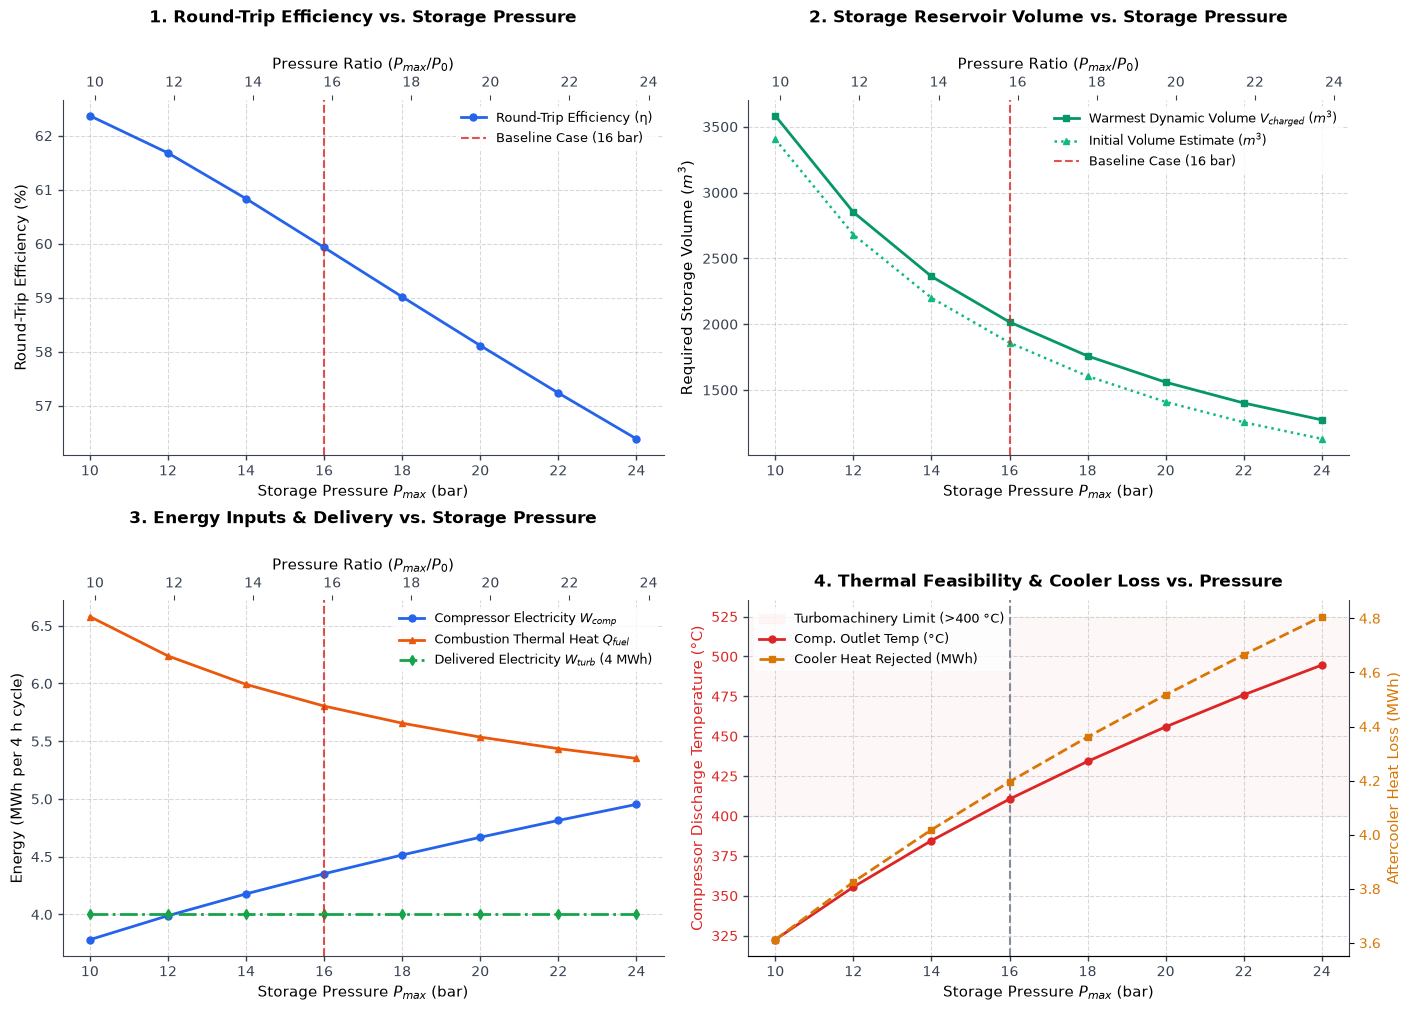

In [ ]:
# =============================================================================
# Parametric Study: 4-Panel Visualization & Trade-off Analysis
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

Pmax_sweep_bar = np.array([row["Pmax_bar"] for row in Sweep_Results])
eta_RT_sweep_pct = np.array([row["eta_RT_pct"] for row in Sweep_Results])
V_end_Charge_sweep_m3 = np.array([row["V_end_Charge_m3"] for row in Sweep_Results])
V_start_Discharge_sweep_m3 = np.array([row["V_start_Discharge_m3"] for row in Sweep_Results])
W_comp_Charge_sweep_MWh = np.array([row["W_comp_Charge_MWh"] for row in Sweep_Results])
Q_fuel_Discharge_sweep_MWh = np.array([row["Q_fuel_Discharge_MWh"] for row in Sweep_Results])
W_turb_Discharge_sweep_MWh = np.array([row["W_turb_Discharge_MWh"] for row in Sweep_Results])
T_comp_out_Charge_sweep_C = np.array([row["T_comp_out_Charge_C"] for row in Sweep_Results])
Q_cooler_Charge_sweep_MWh = np.array([row["Q_cooler_Charge_MWh"] for row in Sweep_Results])

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 9,
        "figure.titlesize": 14,
    }
)

Figure_Sweep, Axes_Sweep = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

for axis_sweep in Axes_Sweep.flatten():
    axis_sweep.grid(True, linestyle="--", alpha=0.3, color="gray")
    axis_sweep.spines["top"].set_visible(False)
    axis_sweep.spines["right"].set_visible(False)
    axis_sweep.spines["left"].set_color("#374151")
    axis_sweep.spines["bottom"].set_color("#374151")
    axis_sweep.tick_params(colors="#374151", width=1)

# Round-trip efficiency vs. storage pressure
Axis_Efficiency = Axes_Sweep[0, 0]
Axis_Efficiency.plot(
    Pmax_sweep_bar,
    eta_RT_sweep_pct,
    marker="o",
    markersize=5,
    color="#2563eb",
    linewidth=2.0,
    label="Round-Trip Efficiency (η)",
)
Axis_Efficiency.axvline(
    16.0,
    color="#dc2626",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label="Baseline Case (16 bar)",
)
Axis_Efficiency.set_xlabel("Storage Pressure $P_{max}$ (bar)")
Axis_Efficiency.set_ylabel("Round-Trip Efficiency (%)")
Axis_Efficiency.set_title("1. Round-Trip Efficiency vs. Storage Pressure", pad=25)
Axis_Efficiency.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")

Axis_Efficiency_Ratio = Axis_Efficiency.secondary_xaxis(
    "top",
    functions=(
        lambda pressure_bar: np.array(pressure_bar) * 1e5 / P0,
        lambda pressure_ratio: np.array(pressure_ratio) * P0 / 1e5,
    ),
)
Axis_Efficiency_Ratio.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", labelpad=5)
Axis_Efficiency_Ratio.tick_params(colors="#374151")
Axis_Efficiency_Ratio.spines["top"].set_visible(False)

# Storage reservoir volume vs. storage pressure
Axis_Volume = Axes_Sweep[0, 1]
Axis_Volume.plot(
    Pmax_sweep_bar,
    V_end_Charge_sweep_m3,
    marker="s",
    markersize=5,
    color="#059669",
    linewidth=2.0,
    label="Warmest Dynamic Volume $V_{charged}$ ($m^3$)",
)
Axis_Volume.plot(
    Pmax_sweep_bar,
    V_start_Discharge_sweep_m3,
    marker="^",
    markersize=5,
    color="#10b981",
    linestyle=":",
    linewidth=1.8,
    label="Initial Volume Estimate ($m^3$)",
)
Axis_Volume.axvline(
    16.0,
    color="#dc2626",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label="Baseline Case (16 bar)",
)
Axis_Volume.set_xlabel("Storage Pressure $P_{max}$ (bar)")
Axis_Volume.set_ylabel("Required Storage Volume ($m^3$)")
Axis_Volume.set_title("2. Storage Reservoir Volume vs. Storage Pressure", pad=25)
Axis_Volume.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")

Axis_Volume_Ratio = Axis_Volume.secondary_xaxis(
    "top",
    functions=(
        lambda pressure_bar: np.array(pressure_bar) * 1e5 / P0,
        lambda pressure_ratio: np.array(pressure_ratio) * P0 / 1e5,
    ),
)
Axis_Volume_Ratio.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", labelpad=5)
Axis_Volume_Ratio.tick_params(colors="#374151")
Axis_Volume_Ratio.spines["top"].set_visible(False)

# Energy breakdown
Axis_Energy = Axes_Sweep[1, 0]
Axis_Energy.plot(
    Pmax_sweep_bar,
    W_comp_Charge_sweep_MWh,
    marker="o",
    markersize=5,
    color="#2563eb",
    linewidth=2.0,
    label="Compressor Electricity $W_{comp}$",
)
Axis_Energy.plot(
    Pmax_sweep_bar,
    Q_fuel_Discharge_sweep_MWh,
    marker="^",
    markersize=5,
    color="#ea580c",
    linewidth=2.0,
    label="Combustion Thermal Heat $Q_{fuel}$",
)
Axis_Energy.plot(
    Pmax_sweep_bar,
    W_turb_Discharge_sweep_MWh,
    marker="d",
    markersize=5,
    color="#16a34a",
    linestyle="-.",
    linewidth=2.0,
    label="Delivered Electricity $W_{turb}$ (4 MWh)",
)
Axis_Energy.axvline(16.0, color="#dc2626", linestyle="--", linewidth=1.5, alpha=0.8)
Axis_Energy.set_xlabel("Storage Pressure $P_{max}$ (bar)")
Axis_Energy.set_ylabel("Energy (MWh per 4 h cycle)")
Axis_Energy.set_title("3. Energy Inputs & Delivery vs. Storage Pressure", pad=25)
Axis_Energy.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")

Axis_Energy_Ratio = Axis_Energy.secondary_xaxis(
    "top",
    functions=(
        lambda pressure_bar: np.array(pressure_bar) * 1e5 / P0,
        lambda pressure_ratio: np.array(pressure_ratio) * P0 / 1e5,
    ),
)
Axis_Energy_Ratio.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", labelpad=5)
Axis_Energy_Ratio.tick_params(colors="#374151")
Axis_Energy_Ratio.spines["top"].set_visible(False)

# Compressor outlet temperature and cooler heat rejected
Axis_Temperature = Axes_Sweep[1, 1]
Color_Temperature = "#dc2626"
Color_Cooler_Heat = "#d97706"

Axis_Temperature.axhspan(
    400,
    525,
    color="#fee2e2",
    alpha=0.25,
    zorder=0,
    label="Turbomachinery Limit (>400 °C)",
)
Temperature_Lines = Axis_Temperature.plot(
    Pmax_sweep_bar,
    T_comp_out_Charge_sweep_C,
    marker="o",
    markersize=5,
    color=Color_Temperature,
    linewidth=2.0,
    zorder=2,
    label="Comp. Outlet Temp (°C)",
)
Axis_Temperature.axvline(
    16.0,
    color="#6b7280",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    zorder=1,
)
Axis_Temperature.set_xlabel("Storage Pressure $P_{max}$ (bar)")
Axis_Temperature.set_ylabel(
    "Compressor Discharge Temperature (°C)",
    color=Color_Temperature,
    fontweight="medium",
)
Axis_Temperature.tick_params(axis="y", labelcolor=Color_Temperature)

Axis_Cooler = Axis_Temperature.twinx()
Axis_Cooler.spines["top"].set_visible(False)
Axis_Cooler.spines["left"].set_visible(False)
Axis_Cooler.spines["right"].set_color("#374151")

Cooler_Heat_Lines = Axis_Cooler.plot(
    Pmax_sweep_bar,
    Q_cooler_Charge_sweep_MWh,
    marker="s",
    markersize=5,
    color=Color_Cooler_Heat,
    linewidth=2.0,
    linestyle="--",
    zorder=2,
    label="Cooler Heat Rejected (MWh)",
)
Axis_Cooler.set_ylabel(
    "Aftercooler Heat Loss (MWh)",
    color=Color_Cooler_Heat,
    fontweight="medium",
)
Axis_Cooler.tick_params(axis="y", labelcolor=Color_Cooler_Heat)

Temperature_Handles, Temperature_Labels = Axis_Temperature.get_legend_handles_labels()
Cooler_Handles, Cooler_Labels = Axis_Cooler.get_legend_handles_labels()

Axis_Temperature.legend(
    Temperature_Handles + Cooler_Handles,
    Temperature_Labels + Cooler_Labels,
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="none",
)
Axis_Temperature.set_title("4. Thermal Feasibility & Cooler Loss vs. Pressure", pad=10)

plt.show()